# Imports

In [6]:
import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from tqdm import tqdm
import subprocess

import os, sys
sys.path.append("D:\\DATA\\ActivePIC")
from pathlib import Path

rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import importlib

# Calculate straight-to-bend offsets

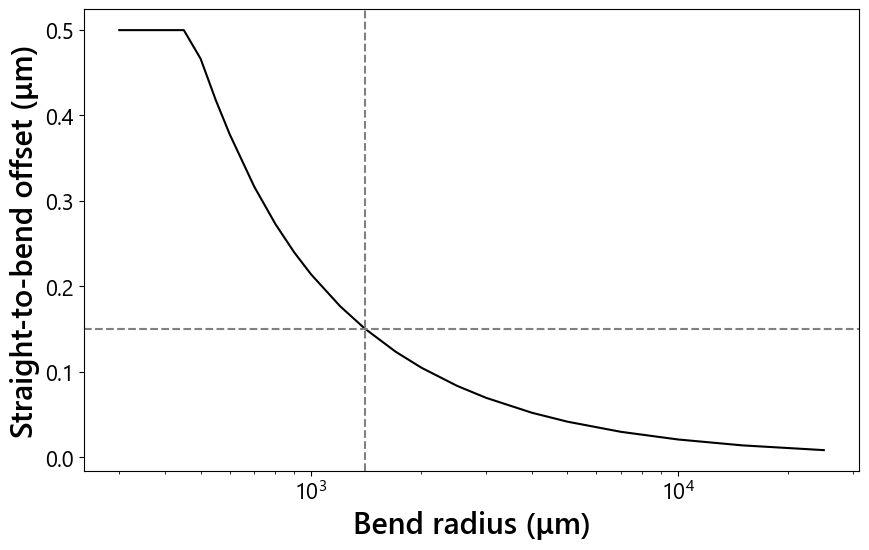

In [10]:
radii = np.load('D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_simulatedBend_neff_table\\StraightWaveguide_simulatedBend_Radius.npy')
offsets = np.array([np.abs(rlib.straight_offset(radius, 1.55, details=True)['offset'])for radius in radii])

plt.figure(figsize=(10,6))
plt.semilogx(radii, offsets, 'k')
plt.axvline(1400, color='gray', linestyle='dashed' )
plt.axhline(0.15, color='gray', linestyle='dashed')
plt.xlabel('Bend radius (μm)')
plt.ylabel('Straight-to-bend offset (μm)')
plt.show()

# BeamPROP: Scan wavelength and bend radius

In [13]:
# Define directories and files to work with
device_name = "P-02_SideStepBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
mode_dir = f"D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_neff_table\\"
save_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav\\"
os.makedirs(save_dir, exist_ok=True)
CAD_path = f"{working_dir}{device_name}.ind"

# Define parameter scan
wav_arr = np.linspace(1.45, 1.65, 11)
# bendRadius_arr = np.linspace(500, 800, 4)
bendRadius_arr = np.arange(600., 900., 100.)
design_wav = 1.55

offsets = np.array([abs(rlib.straight_offset(R, design_wav)) for R in bendRadius_arr])
keep_ext = (".mon", ".json", ".dat")
Grid_Size, Grid_Edge, Step_z = 0.1, 0.5, 0.05

for i, bendRadius in enumerate(tqdm(bendRadius_arr, desc='Bend radius loop', position=0, leave=False)):
    for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False):
        wav_str = rlib.param_str(wav)
        rlib.run_sim(
            CAD_path,
            prefix=f"{save_dir}{device_name}_scan_BendRadius{rlib.param_str(bendRadius)}_Wav{wav_str}",
            symbols={
                "free_space_wavelength": wav,
                "Bend_radius": bendRadius,
                "Straight_offset": offsets[i],
                "Injection_filename": f"{mode_dir}StraightWaveguide_Wav{wav_str}_Width3p400_ex.m00",
                "Grid_Size": Grid_Size,
                "Grid_Edge": Grid_Edge,
                "Step_z": Step_z,
                "pade_order": 4,
                "pade_order_warning_3d": 0
            },
            keep_ext=keep_ext
        )

np.save(f"{save_dir}{device_name}_Wav.npy", wav_arr)
np.save(f"{save_dir}{device_name}_bendRadius.npy", bendRadius_arr)
np.save(f"{save_dir}{device_name}_straightOffset.npy", offsets)

# FemSIM: conduct conformal transform

In [4]:
# Define directories and files to work with
device_name = "P-02_SideStepBend"
CAD_fileroot = "StraightWaveguide_simulatedBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
mode_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\FundamentalMode_lib\\"
save_dir = f"{working_dir}{CAD_fileroot}_scan_BendRadius_Wav\\"
os.makedirs(save_dir, exist_ok=True)
CAD_filename = f"{CAD_fileroot}.ind"

# Define parameter scan
grid_size = 0.05
grid_edge = 0.5
wav_arr = np.linspace(1.45, 1.65, 11)
bendRadius_arr = np.linspace(500, 800, 4)

for bendRadius in tqdm(bendRadius_arr, desc='Radius loop', position=0, leave=False):
    bendRadius_str = f"{bendRadius:0.3f}".replace(".", "p")
    for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
        wav_str = f"{wav:0.3f}".replace(".", "p")
    
        c = RSoftCircuit()
        c.read(working_dir+CAD_filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("simulated_bend_radius", bendRadius)
        c.set_symbol("width", 3.4)
        c.set_symbol("height", 3.4)
        c.set_symbol("Contrast", 1.02)
        c.set_symbol("Grid_x", grid_size)
        c.set_symbol("Grid_y", grid_size)
        c.set_symbol("Grid_z", grid_size)
        c.set_symbol("Grid_Edge", grid_edge)
        c.set_symbol("PML_width", 5)
        c.set_symbol("Volume_transverse", 3.4+10)
        c.write(working_dir+CAD_filename)
        
        command = ["femsim", "-min", CAD_filename, "mode_method=1", "mode_set=1", "idbpm_convergence_warning=0",
                f"prefix={save_dir}{CAD_fileroot}_Wav{wav_str}_Radius{bendRadius_str}", "wait=0"]

        print(f'Wavelength written: {rlib.read_symbol(working_dir+CAD_filename, "free_space_wavelength")}')
        print(f'Radius written: {rlib.read_symbol(working_dir+CAD_filename, "simulated_bend_radius")}')
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

        metadata_name = f'{save_dir}{CAD_fileroot}_bendRadius{bendRadius_str}_Wav{wav_str}.json'
        symbols = rlib.export_symbols(working_dir+CAD_filename, metadata_name)

        filename_nef = f'{save_dir}{CAD_fileroot}_bendRadius{bendRadius_str}_Wav{wav_str}.nef'         
        sim = np.genfromtxt(filename_nef)
        neff = sim[1]
        print(f"n_eff: {neff}")

np.save(f"{save_dir}{CAD_fileroot}_Wav.npy", wav_arr)
np.save(f"{save_dir}{CAD_fileroot}_Radius.npy", bendRadius_arr)

500

# Plot loss vs. wavelength for all circular bend radii

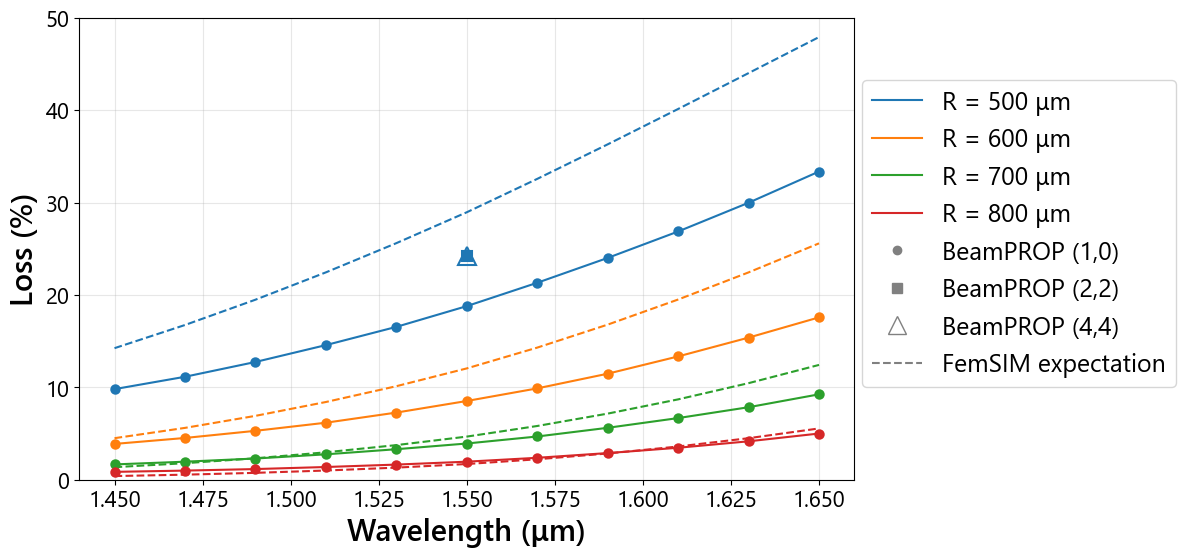

In [32]:
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

import rsoft_lib as rlib

device_name = "P-02_SideStepBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
save_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav\\"
CAD_path = f"{working_dir}{device_name}.ind"

wav_arr = np.load(f"{save_dir}{device_name}_Wav.npy")
bendRadius_arr = np.array([500., 600., 700., 800.])      # set explicitly: the saved _bendRadius.npy only lists the radii of the last scan

# Output plane: use the end of the simulation domain unless you set z_out explicitly
z_out = None  # e.g. z_out = 16002

Bend_offset = rlib.read_symbol(CAD_path, "Bend_offset", cast=float)

# One entry per Padé order: file patterns to try (first existing file wins), marker and size
pade22_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav_pade22\\"        # the production scan folder, if you have run it
series = {
    "(1,0)": dict(marker="o", ms=6, files=lambda t: [f"{save_dir}{device_name}_scan_{t}.mon"]),
    "(2,2)": dict(marker="s", ms=7, files=lambda t: [f"{pade22_dir}{device_name}_scan_{t}.mon",
                                                     f"{save_dir}{device_name}_pade22_{t}.mon"]),
    "(4,4)": dict(marker="^", ms=13, files=lambda t: [f"{save_dir}{device_name}_pade44_{t}.mon"]),
}


def loss_percent(candidates):
    """Loss (%) at the output plane from the first existing monitor file, NaN if none exists."""
    for path in candidates:
        if os.path.exists(path):
            return (1 - rlib.read_monitor(path).at(z_out)[0]) * 100
    return np.nan


measured = {name: np.full((len(bendRadius_arr), len(wav_arr)), np.nan) for name in series}   # simulated loss (%)
expected = np.full((len(bendRadius_arr), len(wav_arr)), np.nan)                                # loss expected from the bend-loss table (%)
for i, R in enumerate(bendRadius_arr):
    expected[i] = rlib.sbend_loss(R, Bend_offset, wav_arr)[1] * 100                # fraction of power lost -> %
    for j, wav in enumerate(wav_arr):
        tag = f"BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}"
        for name, s in series.items():
            measured[name][i, j] = loss_percent(s["files"](tag))

plt.figure(figsize=(10, 6))
for i, R in enumerate(bendRadius_arr):
    for name, s in series.items():
        n_points = np.isfinite(measured[name][i]).sum()
        plt.plot(wav_arr, measured[name][i], color=f'C{i}', marker=s["marker"], markersize=s["ms"],
                 markerfacecolor="none" if name == "(4,4)" else f'C{i}', markeredgewidth=1.5,
                 linestyle="-" if (name == "(1,0)" or n_points > 1) else "none")     # a single point gets no line
    plt.plot(wav_arr, expected[i], linestyle='dashed', color=f'C{i}')

handles = [Line2D([], [], color=f"C{i}", label=f"R = {R:.0f} μm") for i, R in enumerate(bendRadius_arr)]
handles += [Line2D([], [], color="gray", marker=s["marker"], markersize=s["ms"], linestyle="none",
                   markerfacecolor="none" if name == "(4,4)" else "gray", label=f"BeamPROP {name}")
            for name, s in series.items()]
handles.append(Line2D([], [], color="gray", linestyle="dashed", label="FemSIM expectation"))
plt.xlabel('Wavelength (μm)')
plt.ylabel('Loss (%)')
plt.legend(handles=handles, loc=(1.01, 0.2))
plt.grid(alpha=0.3)
plt.ylim(0, 50)
plt.show()

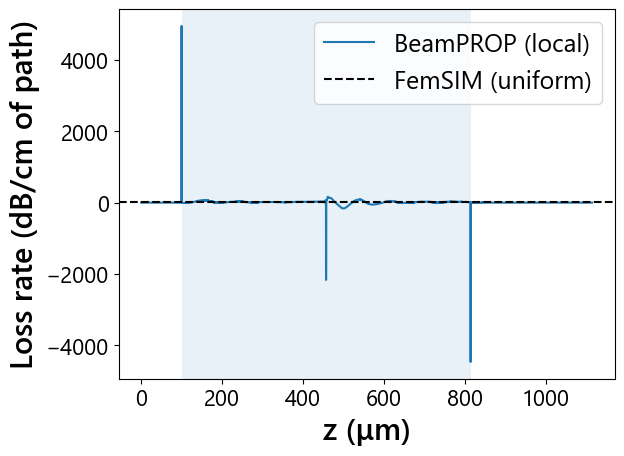

In [13]:
def local_loss_dB_per_cm(z, P, R, d, z_start):
    """Loss rate per unit PATH length (dB/cm) along a circular S-bend, from the power trace P(z)."""
    arc, Z, theta = rlib.sbend_lengths(R, d)
    zr = np.clip(z - z_start, 0, Z)                              # position inside the bend
    dBdz = np.gradient(-10 * np.log10(P), z)                     # dB per μm of z
    cosphi = np.sqrt(1 - (np.minimum(zr, Z - zr) / R) ** 2)      # ds = dz / cos(phi)
    return dBdz * cosphi * 1e4

R, wav = 500, 1.55
mon = rlib.read_monitor(f"{save_dir}{device_name}_scan_BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}.mon")
z, P = mon.z - mon.z[0], mon.values[:, 0]
Input_length = rlib.read_symbol(CAD_path, "Input_length", cast=float)       # assumes the bend starts here
loss_local = local_loss_dB_per_cm(z, P, R, Bend_offset, Input_length)

plt.plot(z, loss_local, label="BeamPROP (local)")
plt.axhline(rlib.get_loss(R, wav), color="k", linestyle="dashed", label="FemSIM (uniform)")
plt.axvspan(Input_length, Input_length + rlib.sbend_lengths(R, Bend_offset)[1], alpha=0.1)
plt.xlabel("z (μm)"); plt.ylabel("Loss rate (dB/cm of path)"); plt.legend(); plt.show()

bend start  (z =  100.0 um): step of +0.197 dB
inflection  (z =  457.1 um): step of -0.073 dB
bend end    (z =  814.1 um): step of -0.174 dB
cumulative loss at the end: BeamPROP 0.904 dB, FemSIM rate x length 1.484 dB


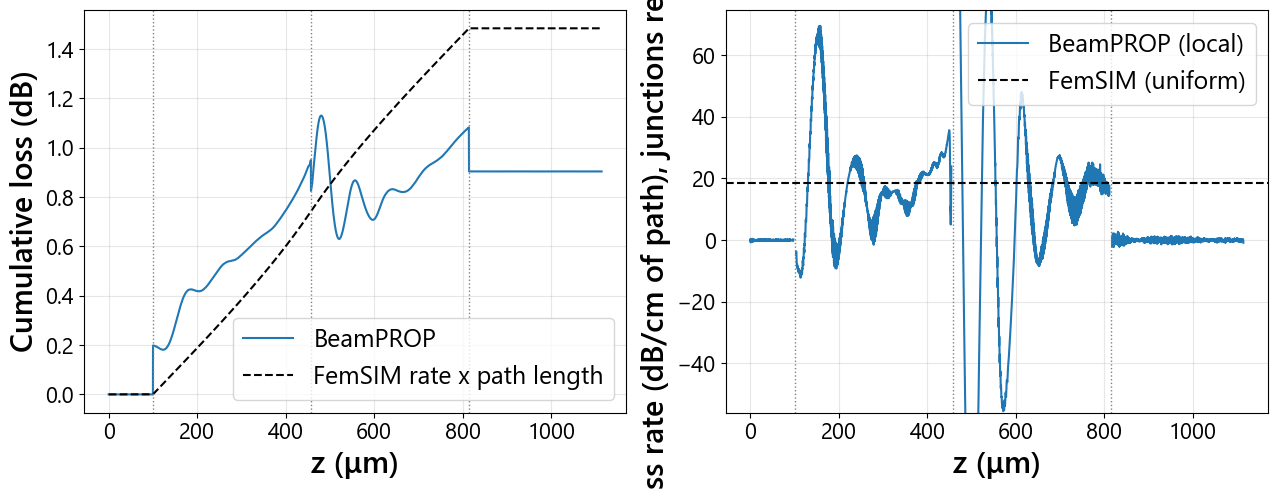

In [16]:
import matplotlib.pyplot as plt
import numpy as np

import rsoft_lib as rlib

R, wav = 500, 1.55
mon = rlib.read_monitor(f"{save_dir}{device_name}_scan_BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}.mon")
z, P = mon.z - mon.z[0], mon.values[:, 0]
z_start = rlib.read_symbol(CAD_path, "Input_length", cast=float)               # assumes the bend starts here
arc, Z, theta = rlib.sbend_lengths(R, Bend_offset)

# position along the path (um): 0 before the bend, arc length after it
zr = np.clip(z - z_start, 0, Z)
s = np.where(zr <= Z / 2, R * np.arcsin(np.minimum(zr, Z / 2) / R),
             arc - R * np.arcsin(np.minimum(Z - zr, Z / 2) / R))

loss_dB = -10 * np.log10(P / P[0])                         # cumulative loss relative to the start
expected_dB = rlib.get_loss(R, wav) * s * 1e-4             # FemSIM loss rate x path length

# Local loss rate with the three junction samples removed, so the spikes do not set the y-axis
dBdz = np.gradient(-10 * np.log10(P), z)
local = dBdz * np.sqrt(1 - (np.minimum(zr, Z - zr) / R) ** 2) * 1e4            # dB/cm of path
junctions = z_start + np.array([0, Z / 2, Z])
local[np.min(np.abs(z[:, None] - junctions[None, :]), axis=1) < 3] = np.nan     # within 3 um of a junction

# Size of the step at each junction (dB), from 3 um before to 3 um after
for name, jz in zip(("bend start", "inflection", "bend end"), junctions):
    step = np.interp(jz + 3, z, loss_dB) - np.interp(jz - 3, z, loss_dB)
    print(f"{name:11s} (z = {jz:6.1f} um): step of {step:+.3f} dB")
print(f"cumulative loss at the end: BeamPROP {loss_dB[-1]:.3f} dB, FemSIM rate x length {expected_dB[-1]:.3f} dB")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(z, loss_dB, label="BeamPROP")
ax[0].plot(z, expected_dB, "k--", label="FemSIM rate x path length")
for jz in junctions:
    ax[0].axvline(jz, color="gray", linestyle=":", linewidth=1)
ax[0].set_xlabel("z (μm)")
ax[0].set_ylabel("Cumulative loss (dB)")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(z, local, label="BeamPROP (local)")
ax[1].axhline(rlib.get_loss(R, wav), color="k", linestyle="dashed", label="FemSIM (uniform)")
ax[1].set_ylim(-3 * rlib.get_loss(R, wav), 4 * rlib.get_loss(R, wav))
for jz in junctions:
    ax[1].axvline(jz, color="gray", linestyle=":", linewidth=1)
ax[1].set_xlabel("z (μm)")
ax[1].set_ylabel("Loss rate (dB/cm of path), junctions removed")
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
L_at = lambda zz: np.interp(zz, z, loss_dB)
arc_half_cm = arc / 2 * 1e-4
rate1 = (L_at(junctions[1] - 3) - L_at(junctions[0] + 3)) / arc_half_cm
rate2 = (L_at(junctions[2] - 3) - L_at(junctions[1] + 3)) / arc_half_cm
print(f"first arc : {rate1:6.1f} dB/cm   second arc: {rate2:6.1f} dB/cm   FemSIM: {rlib.get_loss(R, wav):.1f} dB/cm")

first arc :   18.4 dB/cm   second arc:    5.6 dB/cm   FemSIM: 18.7 dB/cm


In [20]:
import pandas as pd
z_start = rlib.read_symbol(CAD_path, "Input_length", cast=float)               # assumes the bend starts here


def arc_rates(R, wav, margin=3.0):
    """Average loss rate (dB/cm of path) in the first and second arc, with the junction steps left out."""
    mon = rlib.read_monitor(f"{save_dir}{device_name}_scan_BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}.mon")
    z, P = mon.z - mon.z[0], mon.values[:, 0]
    arc, Z, theta = rlib.sbend_lengths(R, Bend_offset)
    j0, j1, j2 = z_start + np.array([0, Z / 2, Z])                             # bend start, inflection, bend end
    L = -10 * np.log10(P / P[0])                                               # cumulative loss (dB)
    L_at = lambda zz: np.interp(zz, z, L)
    half_cm = arc / 2 * 1e-4
    return ((L_at(j1 - margin) - L_at(j0 + margin)) / half_cm,
            (L_at(j2 - margin) - L_at(j1 + margin)) / half_cm)


rows = []
for R in bendRadius_arr:
    for wav in wav_arr:
        try:
            r1, r2 = arc_rates(R, wav)
        except (FileNotFoundError, OSError):
            continue
        femsim = rlib.get_loss(R, wav)
        rows.append(dict(R=R, wav=round(wav, 3), femsim=femsim, first_arc=r1, second_arc=r2,
                         first_over_femsim=r1 / femsim, second_over_femsim=r2 / femsim))
df_arcs = pd.DataFrame(rows)
print(df_arcs.round(2).to_string(index=False))
print("\nMean ratio to the FemSIM rate, by radius:")
print(df_arcs.groupby("R")[["first_over_femsim", "second_over_femsim"]].mean().round(2))

  R  wav  femsim  first_arc  second_arc  first_over_femsim  second_over_femsim
500 1.45    8.39      11.46        0.22               1.37                0.03
500 1.47   10.01      12.44        1.03               1.24                0.10
500 1.49   11.83      13.61        2.02               1.15                0.17
500 1.51   13.88      14.98        3.07               1.08                0.22
500 1.53   16.15      16.58        4.21               1.03                0.26
500 1.55   18.66      18.42        5.56               0.99                0.30
500 1.57   21.51      20.54        7.05               0.96                0.33
500 1.59   24.62      22.98        8.59               0.93                0.35
500 1.61   28.01      25.76       10.26               0.92                0.37
500 1.63   31.67      28.92       12.12               0.91                0.38
500 1.65   35.61      32.49       14.12               0.91                0.40
600 1.45    2.30       5.03       -1.00             

FemSIM expectation: 18.7 dB/cm over 795 um = 1.484 dB

              total (dB)  / expected  arc 1 / FemSIM  arc 2 / FemSIM  max P/P0
(1,0)              0.904        0.61            0.99            0.30    1.0000
(4,4)              1.201        0.81            3.88           -2.43    1.0000

(4,4) run time: 4604 s
The loss moved partway: the Padé order is part of the cause, but something else remains.


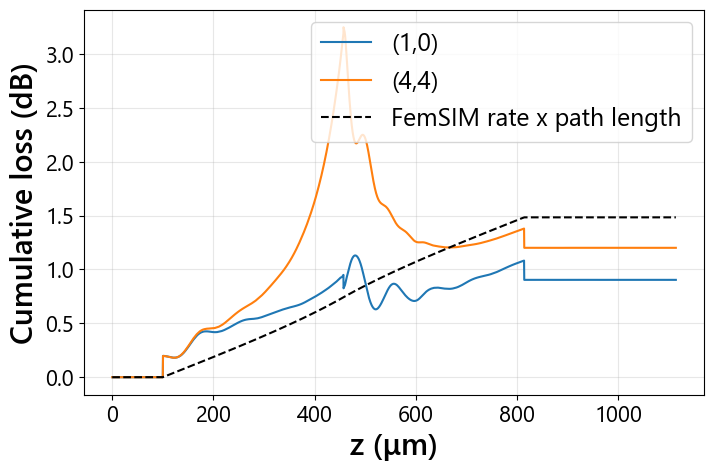

In [23]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np

import rsoft_lib as rlib

R, wav = 500, 1.55
pade_symbols = {}      # e.g. {"<symbol name>": value}; leave empty if (4,4) is already set in the saved .ind

Bend_offset = rlib.read_symbol(CAD_path, "Bend_offset", cast=float)
z_start = rlib.read_symbol(CAD_path, "Input_length", cast=float)           # assumes the bend starts here
tag = f"BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}"
old_prefix = f"{save_dir}{device_name}_scan_{tag}"                          # the existing (1,0) run
new_prefix = f"{save_dir}{device_name}_pade44_{tag}"

# ---- the (4,4) run
S = abs(rlib.straight_offset(R, wav))
t0 = time.perf_counter()
rlib.run_sim(CAD_path, new_prefix, symbols={
    "free_space_wavelength": wav, "Bend_radius": R,
    "Straight_offset": S, "Junction_offset": "2*Straight_offset",           # restores the design relation in case it was overwritten
    "Injection_filename": rlib.mode_field(wav, 3.4)[0], **pade_symbols,
}, keep_ext=(".mon", ".json", ".dat"))
elapsed = time.perf_counter() - t0


# ---- compare with the existing run and with the FemSIM expectation
def analyse(prefix):
    mon = rlib.read_monitor(prefix + ".mon")
    z, P = mon.z - mon.z[0], mon.values[:, 0]
    arc, Z, _ = rlib.sbend_lengths(R, Bend_offset)
    j0, j1, j2 = z_start + np.array([0, Z / 2, Z])                          # bend start, inflection, bend end
    L = -10 * np.log10(P / P[0])                                            # cumulative loss (dB)
    L_at = lambda zz: np.interp(zz, z, L)
    half_cm = arc / 2 * 1e-4
    return dict(z=z, L=L, total=L[-1], pmax=P.max() / P[0],
                arc1=(L_at(j1 - 3) - L_at(j0 + 3)) / half_cm, arc2=(L_at(j2 - 3) - L_at(j1 + 3)) / half_cm)


arc_len = rlib.sbend_lengths(R, Bend_offset)[0]
femsim_rate = rlib.get_loss(R, wav)                                          # dB/cm
expected_total = femsim_rate * arc_len * 1e-4                                # dB
old, new = analyse(old_prefix), analyse(new_prefix)

print(f"FemSIM expectation: {femsim_rate:.1f} dB/cm over {arc_len:.0f} um = {expected_total:.3f} dB\n")
print(f"{'':12s}{'total (dB)':>12s}{'/ expected':>12s}{'arc 1 / FemSIM':>16s}{'arc 2 / FemSIM':>16s}{'max P/P0':>10s}")
for name, r in (("(1,0)", old), ("(4,4)", new)):
    print(f"{name:12s}{r['total']:12.3f}{r['total'] / expected_total:12.2f}"
          f"{r['arc1'] / femsim_rate:16.2f}{r['arc2'] / femsim_rate:16.2f}{r['pmax']:10.4f}")
print(f"\n(4,4) run time: {elapsed:.0f} s")

change = new["total"] / old["total"] - 1
ratio = new["total"] / expected_total
if abs(ratio - 1) < 0.15:
    verdict = "The loss now agrees with FemSIM to within 15%: the Padé order was the main cause."
elif abs(change) < 0.05:
    verdict = "The loss barely changed (< 5%): the Padé order is not the cause."
else:
    verdict = "The loss moved partway: the Padé order is part of the cause, but something else remains."
print(verdict)
if new["pmax"] > 1.01:
    print("Warning: the monitor exceeds its starting value by more than 1%; check the (4,4) run for instability.")

# position along the path (um): 0 before the bend, arc length after it
arc, Z, _ = rlib.sbend_lengths(R, Bend_offset)
zr = np.clip(old["z"] - z_start, 0, Z)
s = np.where(zr <= Z / 2, R * np.arcsin(np.minimum(zr, Z / 2) / R),
             arc - R * np.arcsin(np.minimum(Z - zr, Z / 2) / R))

plt.figure(figsize=(8, 5))
plt.plot(old["z"], old["L"], label="(1,0)")
plt.plot(new["z"], new["L"], label="(4,4)")
plt.plot(old["z"], femsim_rate * s * 1e-4, "k--", label="FemSIM rate x path length")
plt.xlabel("z (μm)")
plt.ylabel("Cumulative loss (dB)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [29]:
R, wav = 500, 1.55
tag = f"BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}"
Bend_offset = rlib.read_symbol(CAD_path, "Bend_offset", cast=float)

# Existing runs are read from their files; a run with settings is only simulated if its .mon file does not exist yet.
runs = {
    "(1,0)": dict(prefix=f"{save_dir}{device_name}_scan_{tag}", symbols=None),                     # existing run
    "(2,2)": dict(prefix=f"{save_dir}{device_name}_pade22_{tag}", symbols={"pade_order": 2}),     # to be run
    # "(3,3)": dict(prefix=f"{save_dir}{device_name}_pade33_{tag}", symbols={"pade_order": 3}),   # if (2,2) is not converged
    "(4,4)": dict(prefix=f"{save_dir}{device_name}_pade44_{tag}", symbols=None),                   # existing run
}

S = abs(rlib.straight_offset(R, wav))
base = {"free_space_wavelength": wav, "Bend_radius": R, "Straight_offset": S,
        "Junction_offset": "2*Straight_offset", "Injection_filename": rlib.mode_field(wav, 3.4)[0],
        "pade_order_warning_3d": 0}

elapsed = {}
for order, r in runs.items():
    print(order, r)
    if os.path.exists(r["prefix"] + ".mon"):
        print(f"{order}: using the existing result")
        continue
    if r["symbols"] is None:
        raise FileNotFoundError(f"{order}: no result at {r['prefix']}.mon and no settings to run it")
    t0 = time.perf_counter()
    rlib.run_sim(CAD_path, r["prefix"], symbols={**base, **r["symbols"]}, keep_ext=(".mon", ".json", ".dat"))
    elapsed[order] = time.perf_counter() - t0

arc_len = rlib.sbend_lengths(R, Bend_offset)[0]
expected = rlib.get_loss(R, wav) * arc_len * 1e-4                      # FemSIM rate x arc length (dB)
total = {}
for order, r in runs.items():
    P = rlib.read_monitor(r["prefix"] + ".mon").values[:, 0]
    total[order] = -10 * np.log10(P[-1] / P[0])                         # loss after the bend (dB): the exit value only

print(f"\nFemSIM expectation: {expected:.3f} dB (steady-state rate x arc length)")
print(f"{'order':8s}{'loss (dB)':>11s}{'/ expected':>12s}{'vs (4,4)':>10s}{'time (s)':>10s}")
for order in runs:
    t = f"{elapsed[order]:10.0f}" if order in elapsed else f"{'':>10s}"
    print(f"{order:8s}{total[order]:11.3f}{total[order] / expected:12.2f}{100 * (total[order] / total['(4,4)'] - 1):9.1f}%{t}")
gap = abs(total["(2,2)"] / total["(4,4)"] - 1)
print(f"\n(2,2) differs from (4,4) by {100 * gap:.1f}%: " +
      ("close enough to use (2,2) for the scan." if gap < 0.05 else "not converged at (2,2); try (3,3) or use (4,4)."))

(1,0) {'prefix': 'D:\\DATA\\NullingPIC_Gen2_sims\\P-02_SideStepBend\\P-02_SideStepBend_scan_BendRadius_Wav\\P-02_SideStepBend_scan_BendRadius500p000_Wav1p550', 'symbols': None}
(1,0): using the existing result
(2,2) {'prefix': 'D:\\DATA\\NullingPIC_Gen2_sims\\P-02_SideStepBend\\P-02_SideStepBend_scan_BendRadius_Wav\\P-02_SideStepBend_pade22_BendRadius500p000_Wav1p550', 'symbols': {'pade_order': 2}}
(4,4) {'prefix': 'D:\\DATA\\NullingPIC_Gen2_sims\\P-02_SideStepBend\\P-02_SideStepBend_scan_BendRadius_Wav\\P-02_SideStepBend_pade44_BendRadius500p000_Wav1p550', 'symbols': None}
(4,4): using the existing result

FemSIM expectation: 1.484 dB (steady-state rate x arc length)
order     loss (dB)  / expected  vs (4,4)  time (s)
(1,0)         0.904        0.61    -24.8%          
(2,2)         1.203        0.81      0.2%      3667
(4,4)         1.201        0.81      0.0%          

(2,2) differs from (4,4) by 0.2%: close enough to use (2,2) for the scan.


In [33]:
import os

import numpy as np

import rsoft_lib as rlib

fem_ind = r"D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_simulatedBend.ind"   # the .ind of the FemSIM bend scan: check the path
out_dir = r"D:\DATA\ActivePIC\SingleWaveguideConvergence\fem_convergence"
os.makedirs(out_dir, exist_ok=True)

R, wav, width, height = 500, 1.55, 3.4, 3.4
base = {"free_space_wavelength": wav, "simulated_bend_radius": R, "width": width, "height": height,
        "Contrast": 1.02, "Grid_x": 0.05, "Grid_y": 0.05, "Grid_z": 0.05, "Grid_Edge": 0.5,
        "PML_width": 5, "Volume_transverse": width + 10}
variants = {                                   # one setting changed per run, FemSIM only (minutes, not hours)
    "baseline": {},
    "domain +10": {"Volume_transverse": width + 20},
    "domain +30": {"Volume_transverse": width + 40},
    "PML 10": {"PML_width": 10},
    "grid 0.025": {"Grid_x": 0.025, "Grid_y": 0.025, "Grid_z": 0.025},
}
keep_ext = (".mon", ".json", ".dat", ".nef", ".m[0-9][0-9]", ".m[0-9][0-9][0-9]")

rates = {}
for name, extra in variants.items():
    root = "conv_" + name.replace(" ", "_").replace("+", "plus")
    prefix = os.path.join(out_dir, f"{root}_Wav{rlib.param_str(wav)}_Radius{rlib.param_str(R)}")
    rlib.run_sim(fem_ind, prefix, symbols={**base, **extra}, exe="femsim",
                 args=["mode_method=1", "mode_set=1", "idbpm_convergence_warning=0"], keep_ext=keep_ext)
    k = rlib.te_mode_index(R, wav, mode_dir=out_dir, root=root)                 # the fundamental TE mode among the computed modes
    nef = np.atleast_2d(np.genfromtxt(prefix + ".nef"))
    rates[name] = float(rlib.loss_dB_per_cm_from_neff_imag(nef[k, 2], wav))     # Im(n_eff) -> dB/cm

print(f"FemSIM loss at R = {R} um, {wav} um (the table value is {rlib.get_loss(R, wav):.1f} dB/cm)\n")
for name, rate in rates.items():
    print(f"{name:12s}{rate:9.2f} dB/cm  ({100 * (rate / rates['baseline'] - 1):+6.1f}% vs baseline)")
spread = max(abs(r / rates["baseline"] - 1) for r in rates.values())
print("\nFemSIM is not converged: its loss depends on the domain, PML or grid." if spread > 0.10 else
      "\nFemSIM loss is stable (within 10%) against domain, PML and grid.")

FemSIM loss at R = 500 um, 1.55 um (the table value is 18.7 dB/cm)

baseline        18.61 dB/cm  (  +0.0% vs baseline)
domain +10      18.70 dB/cm  (  +0.5% vs baseline)
domain +30      18.71 dB/cm  (  +0.5% vs baseline)
PML 10          18.73 dB/cm  (  +0.7% vs baseline)
grid 0.025      18.60 dB/cm  (  -0.0% vs baseline)

FemSIM loss is stable (within 10%) against domain, PML and grid.


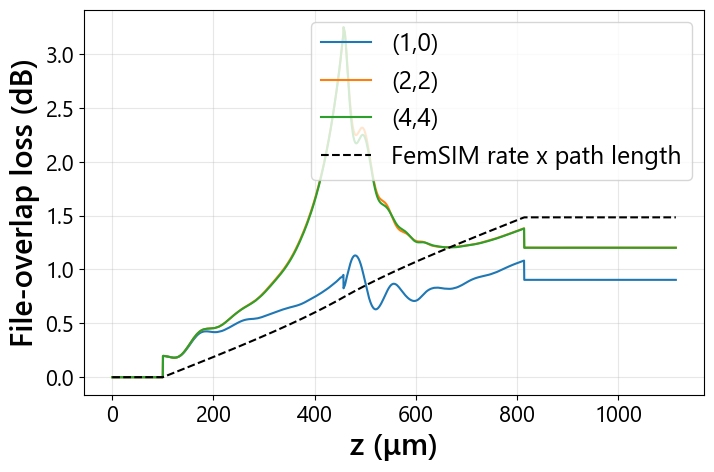

In [38]:
import matplotlib.pyplot as plt
import numpy as np

import rsoft_lib as rlib

R, wav = 500, 1.55
tag = f"BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}"
Bend_offset = rlib.read_symbol(CAD_path, "Bend_offset", cast=float)
z_start = rlib.read_symbol(CAD_path, "Input_length", cast=float)           # assumes the bend starts here
runs = {"(1,0)": f"{save_dir}{device_name}_scan_{tag}",
        "(2,2)": f"{save_dir}{device_name}_pade22_{tag}",
        "(4,4)": f"{save_dir}{device_name}_pade44_{tag}"}

plt.figure(figsize=(8, 5))
for name, prefix in runs.items():
    mon = rlib.read_monitor(prefix + ".mon")                                # existing files: FILE_POWER and FILE_PHASE only
    z, P = mon.z - mon.z[0], mon.values[:, 0]
    plt.plot(z, -10 * np.log10(P / P[0]), label=name)

arc, Z, _ = rlib.sbend_lengths(R, Bend_offset)
zr = np.clip(z - z_start, 0, Z)
s = np.where(zr <= Z / 2, R * np.arcsin(np.minimum(zr, Z / 2) / R), arc - R * np.arcsin(np.minimum(Z - zr, Z / 2) / R))
plt.plot(z, rlib.get_loss(R, wav) * s * 1e-4, "k--", label="FemSIM rate x path length")
plt.xlabel("z (μm)")
plt.ylabel("File-overlap loss (dB)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [37]:
import re
import shutil

import rsoft_lib as rlib

ind = r"D:\DATA\NullingPIC_Gen2_sims\P-02_SideStepBend\P-02_SideStepBend.ind"
shutil.copy(ind, ind + ".bak2")                                    # backup first

with open(ind, newline="") as f:                                   # newline="" keeps the Windows line endings
    text = f.read()

# Header only (everything before the first object block): restore the symbols the conformal test changed
# and remove the simulated-bend setting it added
head_end = re.search(r"(?m)^material \d+", text).start()
head, body = text[:head_end], text[head_end:]
head = re.sub(r"(?m)^simulated_bend_radius\s*=[^\r\n]*(\r?\n)", "", head)
head = re.sub(r"(?m)^Bend_offset\s*=[^\r\n]*", "Bend_offset = 300", head)
head = re.sub(r"(?m)^Junction_offset\s*=[^\r\n]*", "Junction_offset = 2*Straight_offset", head)
with open(ind, "w", newline="") as f:
    f.write(head + body)

symbols = rlib.read_all_symbols(ind)
for name in ("Bend_offset", "Junction_offset", "Straight_offset", "Bend_radius", "pade_order"):
    print(name, "=", symbols.get(name))
print("simulated_bend_radius present:", "simulated_bend_radius" in symbols)

Bend_offset = 300
Junction_offset = 2*Straight_offset
Straight_offset = 0
Bend_radius = 500
pade_order = 2
simulated_bend_radius present: False


In [40]:
import os

import numpy as np
from tqdm.auto import tqdm

import rsoft_lib as rlib

device_name = "P-02_SideStepBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
mode_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_neff_table\\"
pade22_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav_pade22\\"     # where the plotting code looks for (2,2) results
os.makedirs(pade22_dir, exist_ok=True)
CAD_path = f"{working_dir}{device_name}.ind"
design_wav = 1.55

# (radius, wavelength) points, in priority order: a few hours in total instead of the full 33-run scan
points = [(800., 1.55), (500., 1.65), (600., 1.55), (700., 1.55), (500., 1.45)]
# (500, 1.55) already exists from the earlier (2,2) test

for R, wav in tqdm(points, desc="Points"):
    wav_str = rlib.param_str(wav)
    prefix = f"{pade22_dir}{device_name}_scan_BendRadius{rlib.param_str(R)}_Wav{wav_str}"
    if os.path.exists(prefix + ".mon"):                                      # resume: skip finished points
        continue
    S = abs(rlib.straight_offset(R, design_wav))                             # offset designed at 1.55 um, as in the full scan
    rlib.run_sim(
        CAD_path,
        prefix=prefix,
        symbols={
            "free_space_wavelength": wav,
            "Bend_radius": R,
            "Straight_offset": S,
            "Junction_offset": "2*Straight_offset",
            "pade_order": 2,
            "Injection_filename": f"{mode_dir}StraightWaveguide_Wav{wav_str}_Width3p400_ex.m00",
        },
        keep_ext=(".mon", ".json", ".dat"),
    )

c:\Users\runner\anaconda3\envs\rsoft\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Points: 100%|██████████| 5/5 [5:11:06<00:00, 3733.26s/it]  


order     R  wav  simulated_dB  expected_dB  ratio
(2,2) 500.0 1.45         0.593        0.667  0.889
(2,2) 500.0 1.55         1.203        1.484  0.811
(2,2) 500.0 1.65         2.254        2.832  0.796
(2,2) 600.0 1.55         0.579        0.558  1.039
(2,2) 700.0 1.55         0.313        0.208  1.506
(2,2) 800.0 1.55         0.195        0.074  2.622
(4,4) 500.0 1.55         1.201        1.484  0.809

(2,2): 6 points, ratio mean 1.28, min 0.80, max 2.62
The ratio varies with radius or wavelength: the gap is not a single constant factor.


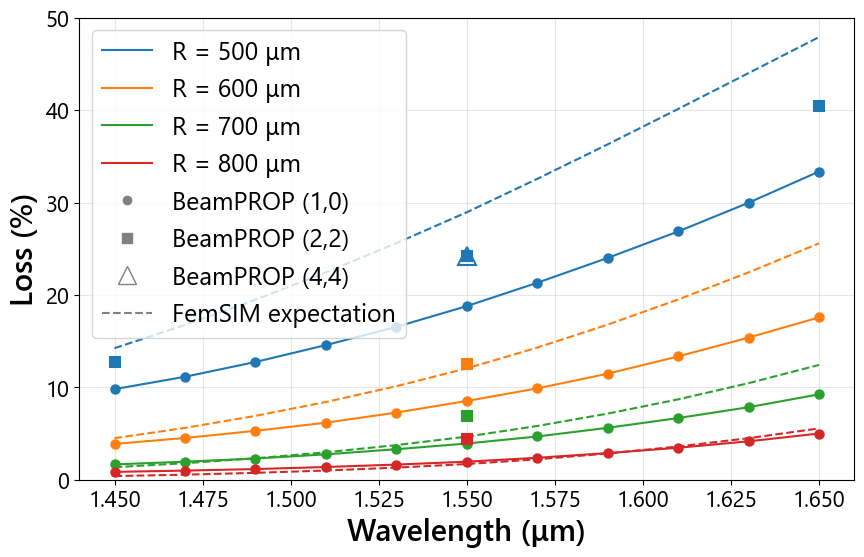

In [41]:
# import os

# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# from matplotlib.lines import Line2D

# import rsoft_lib as rlib

device_name = "P-02_SideStepBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
save_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav\\"
pade22_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav_pade22\\"
CAD_path = f"{working_dir}{device_name}.ind"

wav_arr = np.load(f"{save_dir}{device_name}_Wav.npy")
bendRadius_arr = np.array([500., 600., 700., 800.])
z_out = None                                                  # None: the end of the simulation domain
Bend_offset = rlib.read_symbol(CAD_path, "Bend_offset", cast=float)
assert Bend_offset > 100, f"Bend_offset = {Bend_offset}: the .ind was not restored (should be 300)"

series = {
    "(1,0)": dict(marker="o", ms=6, files=lambda t: [f"{save_dir}{device_name}_scan_{t}.mon"]),
    "(2,2)": dict(marker="s", ms=7, files=lambda t: [f"{pade22_dir}{device_name}_scan_{t}.mon",
                                                     f"{save_dir}{device_name}_pade22_{t}.mon"]),
    "(4,4)": dict(marker="^", ms=13, files=lambda t: [f"{save_dir}{device_name}_pade44_{t}.mon"]),
}


def loss_percent(candidates):
    """Loss (%) at the output plane from the first existing monitor file, NaN if none exists."""
    for path in candidates:
        if os.path.exists(path):
            return (1 - rlib.read_monitor(path).at(z_out)[0]) * 100
    return np.nan


measured = {name: np.full((len(bendRadius_arr), len(wav_arr)), np.nan) for name in series}   # simulated loss (%)
expected = np.full((len(bendRadius_arr), len(wav_arr)), np.nan)                                # FemSIM expectation (%)
for i, R in enumerate(bendRadius_arr):
    expected[i] = rlib.sbend_loss(R, Bend_offset, wav_arr)[1] * 100
    for j, wav in enumerate(wav_arr):
        tag = f"BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}"
        for name, s in series.items():
            measured[name][i, j] = loss_percent(s["files"](tag))

# ---- ratio of the simulated to the expected loss, in dB, for the points that exist
to_dB = lambda p: -10 * np.log10(1 - np.asarray(p) / 100)
rows = []
for name in ("(2,2)", "(4,4)"):
    for i, R in enumerate(bendRadius_arr):
        for j, wav in enumerate(wav_arr):
            if np.isfinite(measured[name][i, j]):
                rows.append(dict(order=name, R=R, wav=round(wav, 3), simulated_dB=to_dB(measured[name][i, j]),
                                 expected_dB=to_dB(expected[i, j]),
                                 ratio=to_dB(measured[name][i, j]) / to_dB(expected[i, j])))
df = pd.DataFrame(rows)
print(df.round(3).to_string(index=False))
d22 = df[df.order == "(2,2)"]
if len(d22) > 1:
    print(f"\n(2,2): {len(d22)} points, ratio mean {d22.ratio.mean():.2f}, min {d22.ratio.min():.2f}, max {d22.ratio.max():.2f}")
    print("Roughly constant: the gap looks systematic." if d22.ratio.max() / d22.ratio.min() < 1.15
          else "The ratio varies with radius or wavelength: the gap is not a single constant factor.")

# ---- comparison plot
plt.figure(figsize=(10, 6))
for i, R in enumerate(bendRadius_arr):
    for name, s in series.items():
        n_points = np.isfinite(measured[name][i]).sum()
        plt.plot(wav_arr, measured[name][i], color=f'C{i}', marker=s["marker"], markersize=s["ms"],
                 markerfacecolor="none" if name == "(4,4)" else f'C{i}', markeredgewidth=1.5,
                 linestyle="-" if (name == "(1,0)" or n_points > 1) else "none")
    plt.plot(wav_arr, expected[i], linestyle='dashed', color=f'C{i}')
handles = [Line2D([], [], color=f"C{i}", label=f"R = {R:.0f} μm") for i, R in enumerate(bendRadius_arr)]
handles += [Line2D([], [], color="gray", marker=s["marker"], markersize=s["ms"], linestyle="none",
                   markerfacecolor="none" if name == "(4,4)" else "gray", label=f"BeamPROP {name}")
            for name, s in series.items()]
handles.append(Line2D([], [], color="gray", linestyle="dashed", label="FemSIM expectation"))
plt.xlabel('Wavelength (μm)')
plt.ylabel('Loss (%)')
plt.legend(handles=handles)
plt.grid(alpha=0.3)
plt.ylim(0, 50)
plt.show()

In [42]:
import os

import numpy as np

import rsoft_lib as rlib

device_name = "P-02_SideStepBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
mode_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_neff_table\\"
pade22_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav_pade22\\"
CAD_path = f"{working_dir}{device_name}.ind"

R, wav = 800., 1.55                      # the largest radius: almost no radiation, so the loss is mostly junction effects
S0 = abs(rlib.straight_offset(R, wav))   # the designed offset
factors = [0.0, 0.5, 1.5, 2.0]           # S and J = 2 S are scaled together; factor 1 is the existing run
tag = f"BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}"

prefixes = {1.0: f"{pade22_dir}{device_name}_scan_{tag}"}
for f in factors:
    prefixes[f] = f"{pade22_dir}{device_name}_offsetscan_f{rlib.param_str(f, 2)}_{tag}"
    if os.path.exists(prefixes[f] + ".mon"):                                  # resume
        continue
    rlib.run_sim(CAD_path, prefixes[f], symbols={
        "free_space_wavelength": wav, "Bend_radius": R,
        "Straight_offset": f * S0, "Junction_offset": "2*Straight_offset",
        "pade_order": 2, "Injection_filename": f"{mode_dir}StraightWaveguide_Wav{rlib.param_str(wav)}_Width3p400_ex.m00",
    }, keep_ext=(".mon", ".json", ".dat"))

print(f"R = {R:.0f} um, {wav} um, designed straight offset {S0:.3f} um, FemSIM expectation {rlib.get_loss(R, wav) * rlib.sbend_lengths(R, 300.0)[0] * 1e-4:.3f} dB")
print(f"{'factor':>7s}{'S (um)':>9s}{'loss (dB)':>11s}")
for f in sorted(prefixes):
    P = rlib.read_monitor(prefixes[f] + ".mon").values[:, 0]
    print(f"{f:7.2f}{f * S0:9.3f}{-10 * np.log10(P[-1] / P[0]):11.3f}")

R = 800 um, 1.55 um, designed straight offset 0.273 um, FemSIM expectation 0.074 dB
 factor   S (um)  loss (dB)
   0.00    0.000      0.486
   0.50    0.136      0.267
   1.00    0.273      0.195
   1.50    0.409      0.270
   2.00    0.545      0.488


In [2]:
import numpy as np

import rsoft_lib as rlib

R, wav = 800., 1.55
s = rlib.straight_offset(R, wav, details=True)          # straight -> arc (and, by symmetry, arc -> straight)
j = rlib.junction_offset(R, wav, details=True)          # arc -> arc
to_dB = lambda eta: -10 * np.log10(eta)

entry, junction = to_dB(s["eta_offset"]), to_dB(j["eta_offset"])
print(f"mismatch at the optimal offset: entry/exit {entry:.4f} dB each, junction {junction:.4f} dB")
print(f"predicted total: {2 * entry + junction:.4f} dB   (the simulated excess over FemSIM: 0.121 dB)")

mismatch at the optimal offset: entry/exit 0.0191 dB each, junction 0.0556 dB
predicted total: 0.0938 dB   (the simulated excess over FemSIM: 0.121 dB)


In [3]:
to_dB = lambda eta: -10 * np.log10(eta)
print(f"{'R (um)':>7s}{'entry/exit':>12s}{'junction':>10s}{'total (dB)':>12s}")
for R in (500., 600., 700., 800.):
    s = rlib.straight_offset(R, 1.55, details=True)
    j = rlib.junction_offset(R, 1.55, details=True)
    entry, junction = to_dB(s["eta_offset"]), to_dB(j["eta_offset"])
    print(f"{R:7.0f}{entry:12.4f}{junction:10.4f}{2 * entry + junction:12.4f}")

 R (um)  entry/exit  junction  total (dB)
    500      0.1040    0.2306      0.4386
    600      0.0549    0.1344      0.2442
    700      0.0317    0.0843      0.1478
    800      0.0191    0.0556      0.0938


In [8]:
import glob
working_dir = "D:\\DATA\\NullingPIC_Gen2_sims\\P-02_SideStepBend\\"
files = glob.glob(os.path.join(working_dir, "**", "*conformal*.mon"), recursive=True)    # finds the file wherever it was saved
print("found:", files)
for path in files:
    mon = rlib.read_monitor(path)
    P = mon.values[:, 0]
    print(f"{os.path.basename(path)}: start {P[0]:.4f}, end {P[-1]:.4f}: {-10 * np.log10(P[-1] / P[0]):.3f} dB lost "
          f"over {mon.z[-1] - mon.z[0]:.0f} um of an (almost) straight guide")

found: ['D:\\DATA\\NullingPIC_Gen2_sims\\P-02_SideStepBend\\P-02_SideStepBend_scan_BendRadius_Wav\\P-02_SideStepBend_conformal_R500p000_Wav1p550.mon']
P-02_SideStepBend_conformal_R500p000_Wav1p550.mon: start 1.0000, end 1.0000: -0.000 dB lost over 404 um of an (almost) straight guide


In [11]:

device_name = "P-02_SideStepBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
mode_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_neff_table\\"
pade22_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav_pade22\\"
CAD_path = f"{working_dir}{device_name}.ind"

R, wav = 800., 1.55                                        # the largest radius: the floor dominates the loss
tag = f"BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}"
S = abs(rlib.straight_offset(R, wav))                      # the designed offset
Bend_offset = rlib.read_symbol(CAD_path, "Bend_offset", cast=float)

baseline = f"{pade22_dir}{device_name}_scan_{tag}"          # the existing run
meta = json.load(open(baseline + ".json"))
fixed = {k: meta[k] for k in ("step_size", "Grid_Size", "Grid_Edge")}   # the settings of the baseline run, passed to every run
print("baseline settings:", fixed)

variants = {                                                # exactly one setting changes in each run
    "step 0.05": {"step_size": 0.05},
    "grid 0.05 only": {"Grid_Size": 0.05},                  # Grid_Edge stays at the baseline value
}
# earlier runs: step 0.1 changed only the step; the first grid run changed Grid_Size to 0.05 AND Grid_Edge from 0.5 to 0.05
earlier = {"step 0.1": "step_0.1", "grid 0.05 and edge 0.05 (first test)": "grid_0.05"}


def prefix_for(name):
    return f"{pade22_dir}{device_name}_convtest_{name.replace(' ', '_')}_{tag}"


original = {k: rlib.read_symbol(CAD_path, k) for k in ("step_size", "Grid_Size", "Grid_Edge")}
for name, extra in variants.items():
    if os.path.exists(prefix_for(name) + ".mon"):           # resume
        continue
    t0 = time.perf_counter()
    rlib.run_sim(CAD_path, prefix_for(name), keep_ext=(".mon", ".json", ".dat"), symbols={
        "free_space_wavelength": wav, "Bend_radius": R,
        "Straight_offset": S, "Junction_offset": "2*Straight_offset", "pade_order": 2,
        "Injection_filename": f"{mode_dir}StraightWaveguide_Wav{rlib.param_str(wav)}_Width3p400_ex.m00",
        **{**fixed, **extra}})
    print(f"{name}: {time.perf_counter() - t0:.0f} s")

# put the settings back in the file
c = rlib.RSoftCircuit()
c.read(CAD_path)
for k, v in original.items():
    c.set_symbol(k, v)
c.write(CAD_path)


def loss_dB(prefix):
    P = rlib.read_monitor(prefix + ".mon").values[:, 0]
    return -10 * np.log10(P[-1] / P[0])


base = loss_dB(baseline)
femsim = rlib.get_loss(R, wav) * rlib.sbend_lengths(R, Bend_offset)[0] * 1e-4
print(f"\nR = {R:.0f} um, {wav} um   (FemSIM radiation alone: {femsim:.3f} dB)")
print(f"baseline (step {fixed['step_size']}, grid {fixed['Grid_Size']}, edge {fixed['Grid_Edge']}): {base:.3f} dB")
results = {}
for name, stem in earlier.items():
    path = f"{pade22_dir}{device_name}_convtest_{stem}_{tag}"
    if os.path.exists(path + ".mon"):
        results[name] = loss_dB(path)
for name in variants:
    if os.path.exists(prefix_for(name) + ".mon"):
        results[name] = loss_dB(prefix_for(name))
for name, L in results.items():
    print(f"{name:>40s}: {L:.3f} dB  (change {L - base:+.3f} dB)")

# the step sequence 0.2, 0.1, 0.05: how fast does the loss converge, and where does it go?
if "step 0.1" in results and "step 0.05" in results:
    a, b, c_ = base, results["step 0.1"], results["step 0.05"]
    if (a - b) * (b - c_) > 0:
        p = np.log2((a - b) / (b - c_))
        L0 = c_ - (b - c_) / (2 ** p - 1)
        print(f"\nStep sequence 0.2, 0.1, 0.05: {a:.3f}, {b:.3f}, {c_:.3f} dB -> order of convergence {p:.2f}, "
              f"extrapolated value for a zero step {L0:.3f} dB")
        print(f"The excess over FemSIM's radiation loss at that value: {L0 - femsim:+.3f} dB")
    else:
        print("\nThe step sequence is not monotonic, so it cannot be extrapolated.")

baseline settings: {'step_size': '0.2', 'Grid_Size': '0.1', 'Grid_Edge': '0.5'}
step 0.05: 9880 s
grid 0.05 only: 14622 s

R = 800 um, 1.55 um   (FemSIM radiation alone: 0.074 dB)
baseline (step 0.2, grid 0.1, edge 0.5): 0.195 dB
                                step 0.1: 0.161 dB  (change -0.034 dB)
    grid 0.05 and edge 0.05 (first test): 0.165 dB  (change -0.030 dB)
                               step 0.05: 0.141 dB  (change -0.054 dB)
                          grid 0.05 only: 0.200 dB  (change +0.005 dB)

Step sequence 0.2, 0.1, 0.05: 0.195, 0.161, 0.141 dB -> order of convergence 0.74, extrapolated value for a zero step 0.111 dB
The excess over FemSIM's radiation loss at that value: +0.036 dB


In [12]:
import json
import os
import time

import numpy as np

import rsoft_lib as rlib

device_name = "P-02_SideStepBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
mode_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_neff_table\\"
pade22_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav_pade22\\"
CAD_path = f"{working_dir}{device_name}.ind"

R, wav = 800., 1.55                                        # the largest radius: the floor dominates the loss
tag = f"BendRadius{rlib.param_str(R)}_Wav{rlib.param_str(wav)}"
S = abs(rlib.straight_offset(R, wav))                      # the designed offset
Bend_offset = rlib.read_symbol(CAD_path, "Bend_offset", cast=float)

baseline = f"{pade22_dir}{device_name}_scan_{tag}"          # the existing run
meta = json.load(open(baseline + ".json"))
fixed = {k: meta[k] for k in ("step_size", "Grid_Size", "Grid_Edge")}   # the settings of the baseline run, passed to every run
print("baseline settings:", fixed)

variants = {                                                # exactly one setting changes, except the last run, which tests whether two effects add
    "edge 0.05 only": {"Grid_Edge": 0.05},                  # the edge factor alone, base grid and step as in the baseline
    "step 0.1 and edge 0.05": {"step_size": 0.1, "Grid_Edge": 0.05},
}
# earlier runs: the step runs and the grid-only run changed exactly one setting; the first grid run changed Grid_Size to 0.05
# AND Grid_Edge from 0.5 to 0.05
earlier = {"step 0.1": "step_0.1", "step 0.05": "step_0.05", "grid 0.05 only": "grid_0.05_only",
           "grid 0.05 and edge 0.05 (first test)": "grid_0.05"}


def prefix_for(name):
    return f"{pade22_dir}{device_name}_convtest_{name.replace(' ', '_')}_{tag}"


original = {k: rlib.read_symbol(CAD_path, k) for k in ("step_size", "Grid_Size", "Grid_Edge")}
for name, extra in variants.items():
    if os.path.exists(prefix_for(name) + ".mon"):           # resume
        continue
    t0 = time.perf_counter()
    rlib.run_sim(CAD_path, prefix_for(name), keep_ext=(".mon", ".json", ".dat"), symbols={
        "free_space_wavelength": wav, "Bend_radius": R,
        "Straight_offset": S, "Junction_offset": "2*Straight_offset", "pade_order": 2,
        "Injection_filename": f"{mode_dir}StraightWaveguide_Wav{rlib.param_str(wav)}_Width3p400_ex.m00",
        **{**fixed, **extra}})
    print(f"{name}: {time.perf_counter() - t0:.0f} s")

# put the settings back in the file
c = rlib.RSoftCircuit()
c.read(CAD_path)
for k, v in original.items():
    c.set_symbol(k, v)
c.write(CAD_path)


def loss_dB(prefix):
    P = rlib.read_monitor(prefix + ".mon").values[:, 0]
    return -10 * np.log10(P[-1] / P[0])


base = loss_dB(baseline)
femsim = rlib.get_loss(R, wav) * rlib.sbend_lengths(R, Bend_offset)[0] * 1e-4
print(f"\nR = {R:.0f} um, {wav} um   (FemSIM radiation alone: {femsim:.3f} dB)")
print(f"baseline (step {fixed['step_size']}, grid {fixed['Grid_Size']}, edge {fixed['Grid_Edge']}): {base:.3f} dB")
results = {}
for name, stem in earlier.items():
    path = f"{pade22_dir}{device_name}_convtest_{stem}_{tag}"
    if os.path.exists(path + ".mon"):
        results[name] = loss_dB(path)
for name in variants:
    if os.path.exists(prefix_for(name) + ".mon"):
        results[name] = loss_dB(prefix_for(name))
for name, L in results.items():
    print(f"{name:>40s}: {L:.3f} dB  (change {L - base:+.3f} dB)")

# do the step and edge effects add?
if all(k in results for k in ("step 0.1", "edge 0.05 only", "step 0.1 and edge 0.05")):
    expected = results["step 0.1"] + (results["edge 0.05 only"] - base)
    print(f"\nIf the step and edge effects added, step 0.1 with edge 0.05 would give {expected:.3f} dB; it gave "
          f"{results['step 0.1 and edge 0.05']:.3f} dB.")

# the step sequence 0.2, 0.1, 0.05: how fast does the loss converge, and where does it go?
if "step 0.1" in results and "step 0.05" in results:
    a, b, c_ = base, results["step 0.1"], results["step 0.05"]
    if (a - b) * (b - c_) > 0:
        p = np.log2((a - b) / (b - c_))
        L0 = c_ - (b - c_) / (2 ** p - 1)
        print(f"\nStep sequence 0.2, 0.1, 0.05: {a:.3f}, {b:.3f}, {c_:.3f} dB -> order of convergence {p:.2f}, "
              f"extrapolated value for a zero step {L0:.3f} dB")
        print(f"The excess over FemSIM's radiation loss at that value: {L0 - femsim:+.3f} dB")
    else:
        print("\nThe step sequence is not monotonic, so it cannot be extrapolated.")

baseline settings: {'step_size': '0.2', 'Grid_Size': '0.1', 'Grid_Edge': '0.5'}
edge 0.05 only: 3452 s
step 0.1 and edge 0.05: 13178 s

R = 800 um, 1.55 um   (FemSIM radiation alone: 0.074 dB)
baseline (step 0.2, grid 0.1, edge 0.5): 0.195 dB
                                step 0.1: 0.161 dB  (change -0.034 dB)
                               step 0.05: 0.141 dB  (change -0.054 dB)
                          grid 0.05 only: 0.200 dB  (change +0.005 dB)
    grid 0.05 and edge 0.05 (first test): 0.165 dB  (change -0.030 dB)
                          edge 0.05 only: 0.195 dB  (change +0.000 dB)
                  step 0.1 and edge 0.05: 0.161 dB  (change -0.034 dB)

If the step and edge effects added, step 0.1 with edge 0.05 would give 0.161 dB; it gave 0.161 dB.

Step sequence 0.2, 0.1, 0.05: 0.195, 0.161, 0.141 dB -> order of convergence 0.74, extrapolated value for a zero step 0.111 dB
The excess over FemSIM's radiation loss at that value: +0.036 dB


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import rsoft_lib as rlib

working_dir = "D:\\DATA\\ActivePIC\\Tricoupler\\"
data_dir = f"{working_dir}tricoupler_passive_data\\"                  # measured splitting: Tricoupler_couplingLength{L}_input{A,B,C}.txt
filename_root = "Tricoupler_FiberOneInput"

coupling_lengths = [278, 308, 338]
inputs = ["A", "B", "C"]
target_wavs = [1450, 1550, 1650]                                       # nm; must be among the wavelengths of the scan
widths = np.linspace(3.2, 3.6, 5)                                      # the widths of the scan (the .npy is only saved when a coupling length finishes)


def sim_folder(coupling_length):
    return f"{working_dir}Tricoupler_passive_sim\\{filename_root}_couplingLength{coupling_length}_scan_Wav_Width\\"


def read_sim(coupling_length, input_name, width, wav_um):
    """(fractions of the total power in outputs A, B, C, last z) of one simulation, or None if it has not run."""
    path = (f"{sim_folder(coupling_length)}{filename_root}_couplingLength{coupling_length}_input{input_name}"
            f"_Width{rlib.param_str(width, 2)}_Wav{rlib.param_str(wav_um)}.mon")
    try:
        mon = rlib.read_monitor(path)
    except (OSError, ValueError):
        return None
    power_cols = [i for i, t in enumerate(mon.type) if t == "FILE_POWER"]
    if len(power_cols) != 3:
        raise ValueError(f"Expected 3 power monitors (outputs A, B, C), found the monitor types {mon.type}")
    p = mon.values[-1, power_cols]
    return p / p.sum(), mon.z[-1]


def best_width(w, y):
    """Width at the minimum of the finished points; a parabola through the lowest point and its neighbours refines it.
    A minimum at the end of a scan that is still running is not a minimum yet, so it returns None."""
    ok = np.isfinite(y)
    complete = ok.all()
    w, y = w[ok], y[ok]
    if len(y) < 3:
        return None
    k = int(np.argmin(y))
    if 0 < k < len(y) - 1:
        a, b, _ = np.polyfit(w[k - 1:k + 2], y[k - 1:k + 2], 2)
        if a > 0:
            return -b / (2 * a)
    return w[k] if complete else None


# measured data (read each file once)
data = {(L, name): np.genfromtxt(f"{data_dir}Tricoupler_couplingLength{L}_input{name}.txt", names=True, delimiter=',')
        for L in coupling_lengths for name in inputs}

# simulations that exist so far; a run that stops short in z (still running) is ignored
sims = {}
for L in coupling_lengths:
    found = {}
    for name in inputs:
        for target in target_wavs:
            for i, w in enumerate(widths):
                result = read_sim(L, name, w, target / 1000)
                if result is not None:
                    found[(name, target, i)] = result
    if found:
        z_max = max(z for _, z in found.values())
        found = {k: f for k, (f, z) in found.items() if z > z_max - 1.0}
    sims.update({(L,) + k: f for k, f in found.items()})
    print(f"Coupling length {L}: {len(found)} of {len(inputs) * len(target_wavs) * len(widths)} runs available")

# least squares of the difference in splitting fractions, for every width that has run
lsq = {}
for L in coupling_lengths:
    for name in inputs:
        for target in target_wavs:
            row = data[(L, name)][np.isclose(data[(L, name)]['wav'], target, atol=0.1)]
            measured = np.array([row['outputA'][0], row['outputB'][0], row['outputC'][0]])
            measured = measured / measured.sum()
            lsq[(L, name, target)] = np.array([np.sum((sims[(L, name, target, i)] - measured) ** 2)
                                               if (L, name, target, i) in sims else np.nan for i in range(len(widths))])
if not any(np.isfinite(y).any() for y in lsq.values()):
    raise RuntimeError("No finished simulations found yet.")

# plot
ymax = 1.1 * max(np.nanmax(y) for y in lsq.values() if np.isfinite(y).any())
fig, ax = plt.subplots(3, 3, figsize=(14, 14), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.12, hspace=0)
best = {}
for row_i, L in enumerate(coupling_lengths):
    for col, name in enumerate(inputs):
        for i_wav, target in enumerate(target_wavs):
            y = lsq[(L, name, target)]
            if not np.isfinite(y).any():
                continue
            line, = ax[row_i, col].plot(widths, y, 'o-', color=f'C{i_wav}', label=f'{target} nm')
            w_best = best_width(widths, y)
            best[(L, name, target)] = w_best
            if w_best is not None:                                      # needs a minimum inside the finished widths
                ax[row_i, col].axvline(w_best, linestyle='--', linewidth=1, color=line.get_color())
                ax[row_i, col].text(w_best, 0.95 - 0.09 * i_wav, f'{w_best:.2f} μm', transform=ax[row_i, col].get_xaxis_transform(),
                                    ha='center', va='top', color=line.get_color(), fontsize=11, fontweight='bold',
                                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
        ax[row_i, col].set(ylim=(0, ymax))
        ax[row_i, col].set_xticks(widths)
    ax[row_i, 1].text(0.5, 0.5, f'Coupling length: {L} μm', transform=ax[row_i, 1].transAxes, ha='center', va='center',
                      fontsize=16, fontweight='bold', alpha=0.25)
for col, name in enumerate(inputs):
    ax[0, col].set_title(f'Input {name}')
ax[0, 2].legend(fontsize=16, title='Wavelength')
ax[2, 1].set_xlabel('Waveguide width (μm)')
ax[1, 0].set_ylabel('Least squares of differences in data and sim')
plt.show()

print("\nBest width (μm) for each coupling length, input and wavelength ('-' = no minimum found yet in the finished widths)")
print(f"{'L':>5s}{'input':>7s}" + "".join(f"{t:>9d}" for t in target_wavs))
for L in coupling_lengths:
    for name in inputs:
        print(f"{L:5d}{name:>7s}" + "".join(f"{best[(L, name, t)]:9.3f}" if best.get((L, name, t)) is not None else f"{'-':>9s}" for t in target_wavs))